In [1]:

# Install and import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

print("Files uploaded successfully!")


Saving DM01-AUGUST-2026-full-extract.csv to DM01-AUGUST-2026-full-extract.csv
Files uploaded successfully!


In [3]:

import os

files_list = os.listdir("/content")

print("Uploaded files:")
for file in files_list:
    print(file)


Uploaded files:
.config
DM01-AUGUST-2026-full-extract.csv
sample_data


In [5]:
df = pd.read_csv("DM01-AUGUST-2026-full-extract.csv")

display(df.head())
print(df.columns.tolist())
print(df.shape)

,Period,Provider Parent Org Code,Provider Parent Name,Provider Org Code,Provider Org Name,Commissioner Parent Org Code,Commissioner Parent Name,Commissioner Org Code,Commissioner Org Name,Diagnostic Tests Sort Order,...,09 < 10 Weeks,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity
0,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,1,...,0,0,0,0,0,0,0,0,0,0
1,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,2,...,0,0,0,0,0,0,0,0,0,0
2,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,3,...,0,0,0,0,0,0,1,0,0,1
3,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,4,...,0,0,0,0,0,0,0,0,0,0
4,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,5,...,0,0,0,0,0,0,0,0,0,0


['Period', 'Provider Parent Org Code', 'Provider Parent Name', 'Provider Org Code', 'Provider Org Name', 'Commissioner Parent Org Code', 'Commissioner Parent Name', 'Commissioner Org Code', 'Commissioner Org Name', 'Diagnostic Tests Sort Order', 'Diagnostic Tests', '00 < 01 Week', '01 < 02 Weeks', '02 < 03 Weeks', '03 < 04 Weeks', '04 < 05 Weeks', '05 < 06 Weeks', '06 < 07 Weeks', '07 < 08 Weeks', '08 < 09 Weeks', '09 < 10 Weeks', '10 < 11 Weeks', '11 < 12 Weeks', '12 < 13 Weeks', '13+ Weeks', 'Total WL', 'Waiting List Activity', 'Planned Activity', 'Unscheduled Activity', 'Total Activity']
(150480, 30)


In [7]:

import glob
import pandas as pd
import os

csv_files = glob.glob("/content/*.csv")

dataframes = []

for file in csv_files:
    temp = pd.read_csv(file)
    temp["source_file"] = os.path.basename(file)
    dataframes.append(temp)

combined_df = pd.concat(
    dataframes,
    ignore_index=True
)

print("Combined dataset shape:", combined_df.shape)

display(combined_df.head())


Combined dataset shape: (150480, 31)


,Period,Provider Parent Org Code,Provider Parent Name,Provider Org Code,Provider Org Name,Commissioner Parent Org Code,Commissioner Parent Name,Commissioner Org Code,Commissioner Org Name,Diagnostic Tests Sort Order,...,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity,source_file
0,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,1,...,0,0,0,0,0,0,0,0,0,DM01-AUGUST-2026-full-extract.csv
1,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,2,...,0,0,0,0,0,0,0,0,0,DM01-AUGUST-2026-full-extract.csv
2,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,3,...,0,0,0,0,0,1,0,0,1,DM01-AUGUST-2026-full-extract.csv
3,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,4,...,0,0,0,0,0,0,0,0,0,DM01-AUGUST-2026-full-extract.csv
4,DM01-AUGUST-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,5,...,0,0,0,0,0,0,0,0,0,DM01-AUGUST-2026-full-extract.csv


**Perform data quality checks**

A. Missing values

In [8]:
print(combined_df.isnull().sum())

Period                             0
Provider Parent Org Code           0
Provider Parent Name               0
Provider Org Code                  0
Provider Org Name                  0
Commissioner Parent Org Code    4016
Commissioner Parent Name        4016
Commissioner Org Code              0
Commissioner Org Name           1888
Diagnostic Tests Sort Order        0
Diagnostic Tests                   0
00 < 01 Week                       0
01 < 02 Weeks                      0
02 < 03 Weeks                      0
03 < 04 Weeks                      0
04 < 05 Weeks                      0
05 < 06 Weeks                      0
06 < 07 Weeks                      0
07 < 08 Weeks                      0
08 < 09 Weeks                      0
09 < 10 Weeks                      0
10 < 11 Weeks                      0
11 < 12 Weeks                      0
12 < 13 Weeks                      0
13+ Weeks                          0
Total WL                           0
Waiting List Activity              0
P

B. Duplicate records

In [9]:
print(
    "Duplicate rows:",
    combined_df.duplicated().sum()
)

Duplicate rows: 0


C. Dataset information

In [10]:
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150480 entries, 0 to 150479
Data columns (total 31 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Period                        150480 non-null  object
 1   Provider Parent Org Code      150480 non-null  object
 2   Provider Parent Name          150480 non-null  object
 3   Provider Org Code             150480 non-null  object
 4   Provider Org Name             150480 non-null  object
 5   Commissioner Parent Org Code  146464 non-null  object
 6   Commissioner Parent Name      146464 non-null  object
 7   Commissioner Org Code         150480 non-null  object
 8   Commissioner Org Name         148592 non-null  object
 9   Diagnostic Tests Sort Order   150480 non-null  int64 
 10  Diagnostic Tests              150480 non-null  object
 11  00 < 01 Week                  150480 non-null  int64 
 12  01 < 02 Weeks                 150480 non-null  int64 
 13 

D. Statistical summary

In [11]:
display(combined_df.describe(include="all"))

,Period,Provider Parent Org Code,Provider Parent Name,Provider Org Code,Provider Org Name,Commissioner Parent Org Code,Commissioner Parent Name,Commissioner Org Code,Commissioner Org Name,Diagnostic Tests Sort Order,...,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity,source_file
count,150480,150480,150480,150480,150480,146464,146464,150480,148592,150480.000000,...,150480.000000,150480.000000,150480.00000,150480.000000,150480.000000,150480.000000,150480.000000,150480.000000,150480.000000,150480
unique,1,36,36,458,457,36,36,108,107,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
top,DM01-AUGUST-2026,Z9B2Z,NHS WEST AND NORTH LONDON INTEGRATED CARE BOARD,RXW,UNIVERSITY HOSPITALS COVENTRY AND WARWICKSHIRE...,QOP,NHS GREATER MANCHESTER INTEGRATED CARE BOARD,W2U3Z,NHS WEST AND NORTH LONDON ICB - W2U3Z,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DM01-AUGUST-2026-full-extract.csv
freq,150480,14240,14240,1728,1728,12400,12400,2320,2320,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,150480
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.500000,...,0.440524,0.371863,0.29778,1.883825,24.362972,22.831114,3.330423,7.290922,33.452459,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.609788,...,11.320305,10.265434,8.54822,60.447156,412.350726,365.017482,56.009643,145.552799,534.133361,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.750000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.500000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.250000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN


**Clean the dataset**

In [12]:
combined_df.columns = (
    combined_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(combined_df.columns.tolist())

['period', 'provider_parent_org_code', 'provider_parent_name', 'provider_org_code', 'provider_org_name', 'commissioner_parent_org_code', 'commissioner_parent_name', 'commissioner_org_code', 'commissioner_org_name', 'diagnostic_tests_sort_order', 'diagnostic_tests', '00_<_01_week', '01_<_02_weeks', '02_<_03_weeks', '03_<_04_weeks', '04_<_05_weeks', '05_<_06_weeks', '06_<_07_weeks', '07_<_08_weeks', '08_<_09_weeks', '09_<_10_weeks', '10_<_11_weeks', '11_<_12_weeks', '12_<_13_weeks', '13+_weeks', 'total_wl', 'waiting_list_activity', 'planned_activity', 'unscheduled_activity', 'total_activity', 'source_file']


In [14]:

from google.colab import files

uploaded = files.upload()

print("Number of uploaded files:", len(uploaded))

for filename in uploaded.keys():
    print(filename)


Saving DM01-AUGUST-2026-full-extract.csv to DM01-AUGUST-2026-full-extract (1).csv
Saving DM01-MAY-2026-full-extract.csv to DM01-MAY-2026-full-extract.csv
Saving DM01-JUNE-2026-full-extract.csv to DM01-JUNE-2026-full-extract.csv
Saving DM01-JULY-2026-full-extract.csv to DM01-JULY-2026-full-extract.csv
Number of uploaded files: 4
DM01-AUGUST-2026-full-extract (1).csv
DM01-MAY-2026-full-extract.csv
DM01-JUNE-2026-full-extract.csv
DM01-JULY-2026-full-extract.csv


In [15]:

import pandas as pd
import glob
import os

# Find all uploaded CSV files
csv_files = glob.glob("/content/*.csv")

dataframes = []

for file in csv_files:

    temp = pd.read_csv(file, low_memory=False)

    # Keep the original filename
    temp["source_file"] = os.path.basename(file)

    dataframes.append(temp)

# Combine all monthly files
combined_df = pd.concat(
    dataframes,
    ignore_index=True
)

print("Total files:", len(csv_files))
print("Combined dataset shape:", combined_df.shape)

display(combined_df.head())


Total files: 5
Combined dataset shape: (744256, 31)


,Period,Provider Parent Org Code,Provider Parent Name,Provider Org Code,Provider Org Name,Commissioner Parent Org Code,Commissioner Parent Name,Commissioner Org Code,Commissioner Org Name,Diagnostic Tests Sort Order,...,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity,source_file
0,DM01-MAY-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,1,...,0,0,0,0,0,0,0,0,0,DM01-MAY-2026-full-extract.csv
1,DM01-MAY-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,2,...,0,0,0,0,0,0,0,0,0,DM01-MAY-2026-full-extract.csv
2,DM01-MAY-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,3,...,0,0,0,0,0,3,0,0,3,DM01-MAY-2026-full-extract.csv
3,DM01-MAY-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,4,...,0,0,0,0,0,0,0,0,0,DM01-MAY-2026-full-extract.csv
4,DM01-MAY-2026,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,A0C5S,SPAMEDICA GLOUCESTER,QR1,NHS GLOUCESTERSHIRE INTEGRATED CARE BOARD,11M,NHS GLOUCESTERSHIRE ICB - 11M,5,...,0,0,0,0,0,0,0,0,0,DM01-MAY-2026-full-extract.csv


In [16]:
print(combined_df["Period"].value_counts().sort_index())

Period
DM01-AUGUST-2026    300960
DM01-JULY-2026      149088
DM01-JUNE-2026      147216
DM01-MAY-2026       146992
Name: count, dtype: int64


**Prepare provider-level data**

In [17]:

# Convert reporting period into a date

combined_df["month"] = pd.to_datetime(
    combined_df["Period"].str.replace("DM01-", "", regex=False),
    format="%B-%Y"
)

# Identify numerical waiting-time and activity columns
waiting_columns = [
    "00 < 01 Week",
    "01 < 02 Weeks",
    "02 < 03 Weeks",
    "03 < 04 Weeks",
    "04 < 05 Weeks",
    "05 < 06 Weeks",
    "06 < 07 Weeks",
    "07 < 08 Weeks",
    "08 < 09 Weeks",
    "09 < 10 Weeks",
    "10 < 11 Weeks",
    "11 < 12 Weeks",
    "12 < 13 Weeks",
    "13+ Weeks",
    "Total WL",
    "Waiting List Activity",
    "Planned Activity",
    "Unscheduled Activity",
    "Total Activity"
]

# Aggregate commissioner-level records
# into provider-test-month records

group_columns = [
    "month",
    "Provider Org Code",
    "Provider Org Name",
    "Diagnostic Tests"
]

provider_df = (
    combined_df
    .groupby(group_columns, as_index=False)[waiting_columns]
    .sum()
)

print("Provider-level dataset:", provider_df.shape)

display(provider_df.head())


Provider-level dataset: (29200, 23)


,month,Provider Org Code,Provider Org Name,Diagnostic Tests,00 < 01 Week,01 < 02 Weeks,02 < 03 Weeks,03 < 04 Weeks,04 < 05 Weeks,05 < 06 Weeks,...,09 < 10 Weeks,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity
0,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,AUDIOLOGY_ASSESSMENTS,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,BARIUM_ENEMA,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,COLONOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,CT,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,CYSTOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:

import pandas as pd
import glob
import os

# Find the downloaded monthly files
csv_files = glob.glob("/content/DM01-*-full-extract*.csv")

# Prefer the original filename if duplicate copies exist
csv_files = sorted(
    csv_files,
    key=lambda x: ("(1)" in x, x)
)

dataframes = []
seen_periods = set()
skipped_files = []

for file in csv_files:

    temp = pd.read_csv(file, low_memory=False)

    # Identify the reporting month
    period = temp["Period"].iloc[0]

    # Keep only one file for each month
    if period in seen_periods:
        skipped_files.append(file)
        continue

    seen_periods.add(period)

    temp["source_file"] = os.path.basename(file)

    dataframes.append(temp)

# Rebuild the combined dataset
combined_df = pd.concat(
    dataframes,
    ignore_index=True
)

print("Files included:")
for df in dataframes:
    print(df["source_file"].iloc[0])

print("\nSkipped duplicate files:")
print(skipped_files)

print("\nCorrected dataset shape:", combined_df.shape)

print("\nMonthly records:")
print(combined_df["Period"].value_counts())


Files included:
DM01-AUGUST-2026-full-extract.csv
DM01-JULY-2026-full-extract.csv
DM01-JUNE-2026-full-extract.csv
DM01-MAY-2026-full-extract.csv

Skipped duplicate files:
['/content/DM01-AUGUST-2026-full-extract (1).csv']

Corrected dataset shape: (593776, 31)

Monthly records:
Period
DM01-AUGUST-2026    150480
DM01-JULY-2026      149088
DM01-JUNE-2026      147216
DM01-MAY-2026       146992
Name: count, dtype: int64


In [19]:

# Check duplicate provider-commissioner-test records

check_columns = [
    "Period",
    "Provider Org Code",
    "Commissioner Org Code",
    "Diagnostic Tests"
]

print(
    "Duplicate provider-commissioner-test records:",
    combined_df.duplicated(subset=check_columns).sum()
)


Duplicate provider-commissioner-test records: 0


In [20]:

# Convert reporting period into datetime

combined_df["month"] = pd.to_datetime(
    combined_df["Period"].str.replace(
        "DM01-", "", regex=False
    ),
    format="%B-%Y"
)

# Numeric columns to aggregate
waiting_columns = [
    "00 < 01 Week",
    "01 < 02 Weeks",
    "02 < 03 Weeks",
    "03 < 04 Weeks",
    "04 < 05 Weeks",
    "05 < 06 Weeks",
    "06 < 07 Weeks",
    "07 < 08 Weeks",
    "08 < 09 Weeks",
    "09 < 10 Weeks",
    "10 < 11 Weeks",
    "11 < 12 Weeks",
    "12 < 13 Weeks",
    "13+ Weeks",
    "Total WL",
    "Waiting List Activity",
    "Planned Activity",
    "Unscheduled Activity",
    "Total Activity"
]

# Aggregate commissioner-level records
# to provider-test-month level

group_columns = [
    "month",
    "Provider Org Code",
    "Provider Org Name",
    "Diagnostic Tests"
]

provider_df = (
    combined_df
    .groupby(group_columns, as_index=False)[waiting_columns]
    .sum()
)

print("Provider-level dataset shape:", provider_df.shape)

display(provider_df.head())


Provider-level dataset shape: (29200, 23)


,month,Provider Org Code,Provider Org Name,Diagnostic Tests,00 < 01 Week,01 < 02 Weeks,02 < 03 Weeks,03 < 04 Weeks,04 < 05 Weeks,05 < 06 Weeks,...,09 < 10 Weeks,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity
0,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,AUDIOLOGY_ASSESSMENTS,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,BARIUM_ENEMA,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,COLONOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,CT,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,CYSTOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


**Check the cleaned dataset**

In [21]:
# Display the first five rows
display(provider_df.head())

# Check dataset size
print("Dataset shape:", provider_df.shape)

# Check available months
print("Number of months:", provider_df["month"].nunique())

# Check diagnostic tests
print("Number of diagnostic tests:",
      provider_df["Diagnostic Tests"].nunique())

# Check missing values
print("\nMissing values:")
print(provider_df.isnull().sum())

,month,Provider Org Code,Provider Org Name,Diagnostic Tests,00 < 01 Week,01 < 02 Weeks,02 < 03 Weeks,03 < 04 Weeks,04 < 05 Weeks,05 < 06 Weeks,...,09 < 10 Weeks,10 < 11 Weeks,11 < 12 Weeks,12 < 13 Weeks,13+ Weeks,Total WL,Waiting List Activity,Planned Activity,Unscheduled Activity,Total Activity
0,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,AUDIOLOGY_ASSESSMENTS,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,BARIUM_ENEMA,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,COLONOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,CT,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2026-05-01,A0C5S,SPAMEDICA GLOUCESTER,CYSTOSCOPY,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Dataset shape: (29200, 23)
Number of months: 4
Number of diagnostic tests: 16

Missing values:
month                    0
Provider Org Code        0
Provider Org Name        0
Diagnostic Tests         0
00 < 01 Week             0
01 < 02 Weeks            0
02 < 03 Weeks            0
03 < 04 Weeks            0
04 < 05 Weeks            0
05 < 06 Weeks            0
06 < 07 Weeks            0
07 < 08 Weeks            0
08 < 09 Weeks            0
09 < 10 Weeks            0
10 < 11 Weeks            0
11 < 12 Weeks            0
12 < 13 Weeks            0
13+ Weeks                0
Total WL                 0
Waiting List Activity    0
Planned Activity         0
Unscheduled Activity     0
Total Activity           0
dtype: int64


**Monthly waiting-list trend**

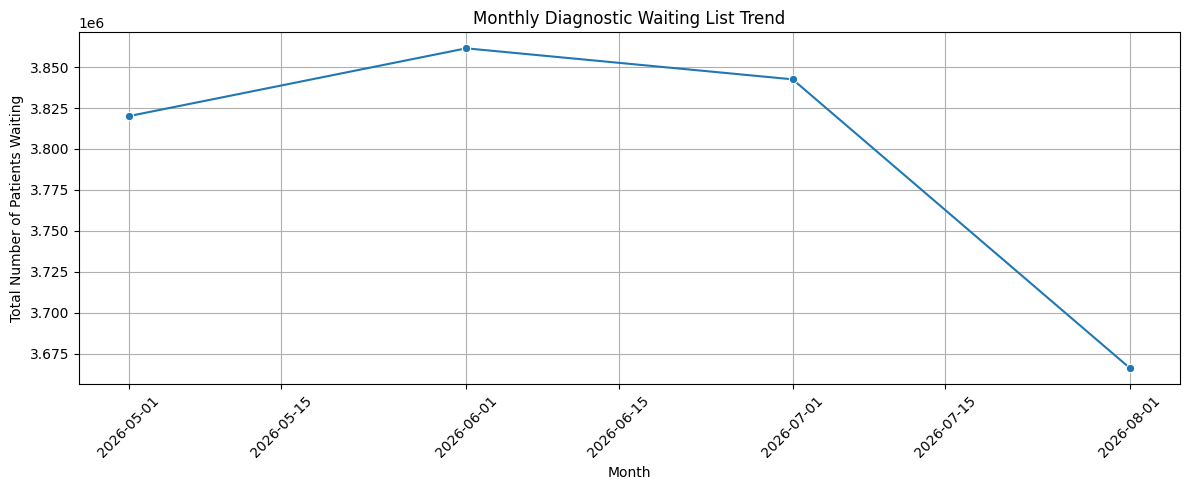

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate monthly total waiting list
monthly_trend = (
    provider_df.groupby("month")["Total WL"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_trend,
    x="month",
    y="Total WL",
    marker="o"
)

plt.title("Monthly Diagnostic Waiting List Trend")
plt.xlabel("Month")
plt.ylabel("Total Number of Patients Waiting")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Compare waiting lists across diagnostic tests**

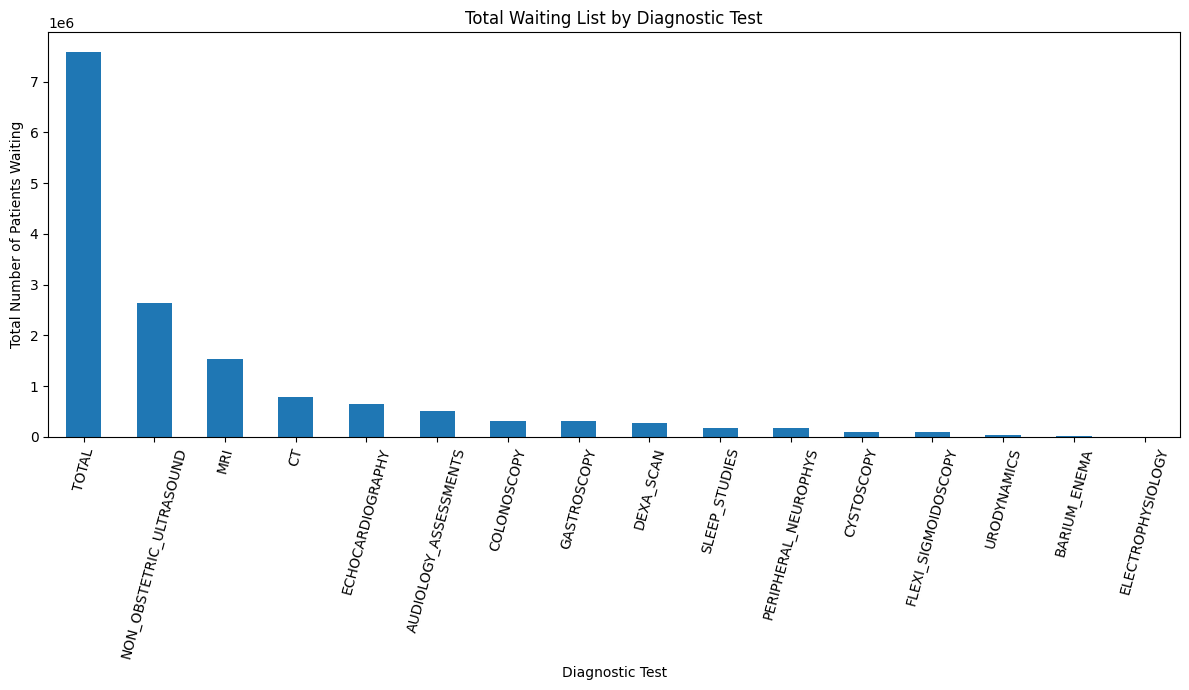

In [23]:
test_waiting = (
    provider_df.groupby("Diagnostic Tests")["Total WL"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

test_waiting.plot(kind="bar")

plt.title("Total Waiting List by Diagnostic Test")
plt.xlabel("Diagnostic Test")
plt.ylabel("Total Number of Patients Waiting")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**Analyse patients waiting 6 weeks or longer**

In [24]:
six_week_columns = [
    "06 < 07 Weeks",
    "07 < 08 Weeks",
    "08 < 09 Weeks",
    "09 < 10 Weeks",
    "10 < 11 Weeks",
    "11 < 12 Weeks",
    "12 < 13 Weeks",
    "13+ Weeks"
]

# Calculate patients waiting 6 weeks or longer
provider_df["Waiting_6plus_Weeks"] = (
    provider_df[six_week_columns].sum(axis=1)
)

print("Total patients waiting 6+ weeks:",
      provider_df["Waiting_6plus_Weeks"].sum())

Total patients waiting 6+ weeks: 3607632


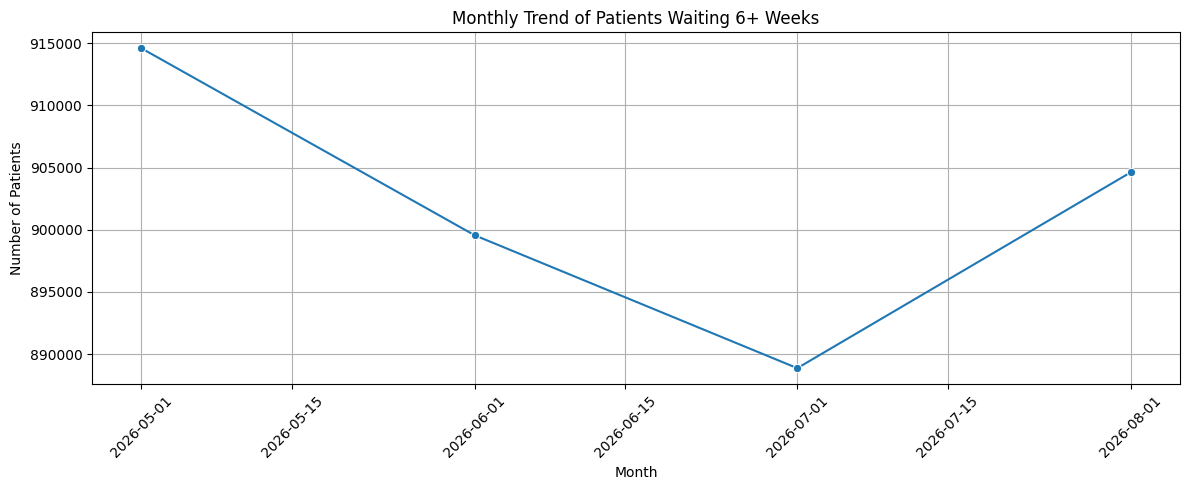

In [25]:
sixplus_trend = (
    provider_df.groupby("month")["Waiting_6plus_Weeks"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=sixplus_trend,
    x="month",
    y="Waiting_6plus_Weeks",
    marker="o"
)

plt.title("Monthly Trend of Patients Waiting 6+ Weeks")
plt.xlabel("Month")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Identify providers with the highest waiting lists**

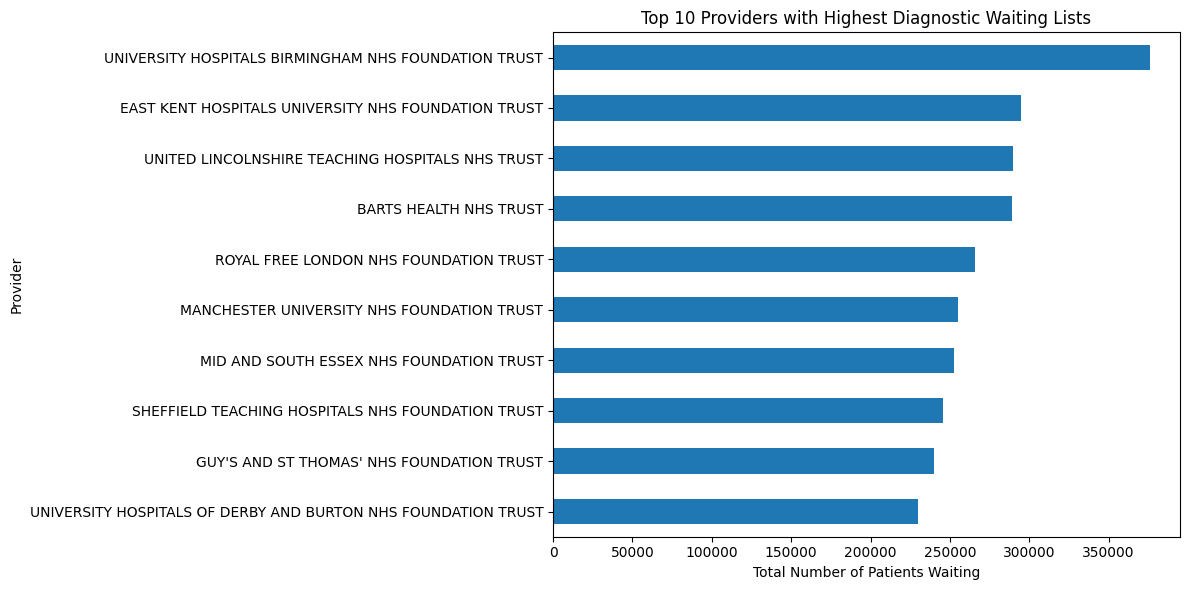

In [26]:
top_providers = (
    provider_df.groupby("Provider Org Name")["Total WL"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_providers.sort_values().plot(kind="barh")

plt.title("Top 10 Providers with Highest Diagnostic Waiting Lists")
plt.xlabel("Total Number of Patients Waiting")
plt.ylabel("Provider")
plt.tight_layout()
plt.show()

**Analyse monthly diagnostic activity**

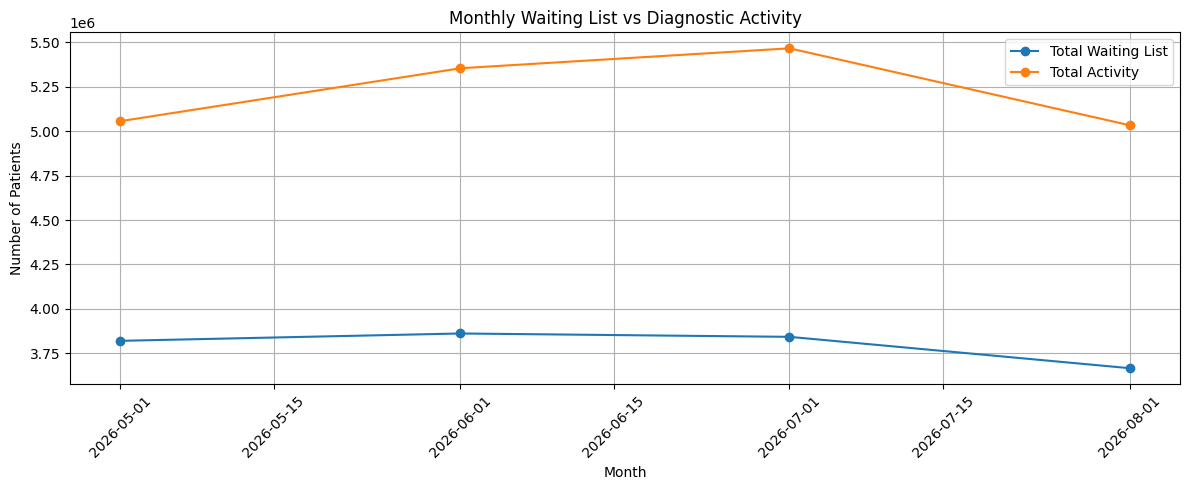

In [27]:
activity_trend = (
    provider_df.groupby("month")[
        ["Total WL", "Total Activity"]
    ]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    activity_trend["month"],
    activity_trend["Total WL"],
    marker="o",
    label="Total Waiting List"
)

plt.plot(
    activity_trend["month"],
    activity_trend["Total Activity"],
    marker="o",
    label="Total Activity"
)

plt.title("Monthly Waiting List vs Diagnostic Activity")
plt.xlabel("Month")
plt.ylabel("Number of Patients")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Save cleaned dataset**

In [28]:
provider_df.to_csv(
    "QueueWise_Cleaned_Provider_Data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [29]:
from google.colab import files

files.download("QueueWise_Cleaned_Provider_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>